# 05. Phân tích mức độ tương đồng biểu diễn giữa ResNet-50 và ViT-B/16

## Mục tiêu nghiên cứu

Độ chính xác phân loại tương đương không nhất thiết phản ánh sự tương đồng trong biểu diễn trung gian của các mô hình. Thí nghiệm sử dụng **Centered Kernel Alignment (CKA)** để so sánh biểu diễn của ResNet-50 và ViT-B/16 trên cùng tập ảnh.

Nghiên cứu tập trung vào hai câu hỏi: **các giai đoạn xử lý của ResNet-50 tương đồng nhất với những khối Transformer nào của ViT-B/16, và mức tương đồng thay đổi như thế nào theo độ sâu mạng?**

Phạm vi phân tích gồm bốn giai đoạn của ResNet-50 và mười hai khối mã hóa của ViT-B/16, được đánh giá trên 10.000 ảnh ImageNet-1K validation. Kết quả bổ sung góc nhìn về biểu diễn đặc trưng cho các thí nghiệm diễn giải và đánh giá độ bền vững của mô hình trong dự án.

## 1. Thiết lập thực nghiệm

Thí nghiệm sử dụng các mô-đun dùng chung của dự án nhằm thống nhất mô hình, tiền xử lý và tập dữ liệu. Các tham số chính được trình bày dưới đây.

| Thành phần | Thiết lập |
| --- | --- |
| Tập phân tích | 10.000 ảnh, 1.000 lớp, 10 ảnh mỗi lớp |
| Seed | 42 |
| Kích thước batch trích xuất | 16 ảnh |
| Kích thước block tính CKA | 512 ảnh |
| Kiểm chứng dữ liệu | SHA-256 của manifest và các tệp dữ liệu nguồn |
| Lưu trữ trung gian | Đặc trưng đã pooling, kèm ID, nhãn và cấu hình trích xuất |

Các đường dẫn và tùy chọn thực thi được tập trung trong phần cấu hình. Cơ chế lưu đặc trưng cho phép tái sử dụng kết quả trích xuất khi cấu hình và tập ảnh không thay đổi.

In [1]:
from pathlib import Path

# Tất cả tham số người dùng chỉnh ở đây.
PROJECT_DIR = None  # None: tự tìm từ cwd; hoặc Path tới repo trên máy local.
DATA_DIR = None     # None: ROOT / "data/imagenet/data"; chứa 14 validation shards.
CACHE_DIR = None    # None: ROOT / "hf_cache"; HF snapshot cache khi tải.
FEATURE_CACHE_DIR = None  # None: ROOT / "outputs/cka_features" (Git ignored).
INSTALL_DEPENDENCIES = False
LOGIN_HF = False
DOWNLOAD_DATA = False
VERIFY_DATA = True  # Hash 6,69 GB một lần ở bước chuẩn bị, không trong inference.
RUN_EXPERIMENT = True
ALLOW_WEIGHT_DOWNLOAD = True
REUSE_FEATURES = True
SAVE_FEATURES = True
CHECK_HOOKS = True
FULL_RUN = True
SMOKE_N = 16       # first-N manifest, chỉ debug; tối thiểu 3 để có ý nghĩa kiểm tra.
SEED = 42
BATCH_SIZE = 16
CKA_BLOCK_SIZE = 512
DEVICE = None      # None: CUDA nếu có, CPU nếu không.
RUN_ID = None      # None: timestamp UTC + UUID; đặt mới khi chạy lại.

import sys
ROOT = Path(PROJECT_DIR).expanduser().resolve() if PROJECT_DIR else Path.cwd().resolve()
if PROJECT_DIR is None and ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "configs/analysis_set.json").is_file():
    raise RuntimeError("Đặt PROJECT_DIR tới repository có configs/analysis_set.json.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
DATA_DIR = Path(DATA_DIR).expanduser().resolve() if DATA_DIR else None
CACHE_DIR = Path(CACHE_DIR) if CACHE_DIR else ROOT / "hf_cache"
FEATURE_CACHE_DIR = Path(FEATURE_CACHE_DIR) if FEATURE_CACHE_DIR else ROOT / "outputs/cka_features"
if INSTALL_DEPENDENCIES:
    import subprocess
    subprocess.run([sys.executable, "-m", "pip", "install", "-r", str(ROOT / "requirements.txt")], check=True)

In [2]:
import csv
import gc
import hashlib
import importlib.metadata
import json
import random
import subprocess
from datetime import datetime, timezone
from uuid import uuid4

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from experiments.cka.cka import (
    RESNET_LAYERS, VIT_LAYERS, LAYER_DIMS, POOLING,
    alignment_order, extract_features, load_or_extract_features,
    linear_cka, cka_matrix, save_results,
)

config = json.loads((ROOT / "configs/analysis_set.json").read_text(encoding="utf-8"))
MANIFEST = ROOT / config["manifest"]
if DATA_DIR is None:
    original_data = ROOT / config["dataset_dir"]
    snapshot_data = (CACHE_DIR / "datasets--ILSVRC--imagenet-1k" / "snapshots"
                     / config["dataset_revision"] / "data")
    DATA_DIR = original_data if original_data.is_dir() else snapshot_data
plt.rcParams["font.family"] = "DejaVu Sans"
MODE = "full" if FULL_RUN else "smoke"
if not FULL_RUN and not 3 <= SMOKE_N < 10000:
    raise ValueError("SMOKE_N phải từ 3 đến 9.999; full run dùng FULL_RUN=True.")
RUN_ID = RUN_ID or f"{MODE}_{datetime.now(timezone.utc):%Y%m%dT%H%M%SZ}_{uuid4().hex[:8]}"
random.seed(SEED)
np.random.seed(SEED)
print("Mode:", MODE, "| Run ID:", RUN_ID, "| Inference enabled:", RUN_EXPERIMENT)

Mode: full | Run ID: full_20261105T011722Z_85319525 | Inference enabled: True


## 2. Phương pháp Centered Kernel Alignment

**Centered Kernel Alignment (CKA)** đo mức tương đồng giữa hai biểu diễn thông qua cấu trúc quan hệ giữa các mẫu. Phương pháp cho phép so sánh các tầng có số chiều đặc trưng khác nhau, phù hợp với việc phân tích CNN và Vision Transformer.

Gọi $X\in\mathbb{R}^{N\times d_X}$ và $Y\in\mathbb{R}^{N\times d_Y}$ là hai ma trận đặc trưng, trong đó các hàng tương ứng với cùng $N$ ảnh theo cùng thứ tự. Sau khi trừ trung bình từng chiều trên toàn bộ tập ảnh, thu được $X_c=X-\mathbf{1}\mu_X^T$ và $Y_c=Y-\mathbf{1}\mu_Y^T$. Linear CKA được xác định bởi:

$$
\mathrm{CKA}(X,Y)=
\frac{\lVert X_c^T Y_c\rVert_F^2}
{\lVert X_c^T X_c\rVert_F\,\lVert Y_c^T Y_c\rVert_F},
$$

trong đó $\lVert\cdot\rVert_F$ là chuẩn Frobenius. Với các biểu diễn không suy biến, CKA nằm trong khoảng $[0,1]$; giá trị lớn hơn thể hiện mức tương đồng cao hơn theo phép đo này. CKA không trực tiếp phản ánh độ chính xác phân loại hoặc cơ chế ra quyết định của mô hình.

Thí nghiệm áp dụng biến thể **biased linear CKA** trên toàn bộ 10.000 ảnh. Để hạn chế bộ nhớ, các tích chéo được tích lũy theo từng khối sau khi định tâm bằng trung bình toàn tập. Cách tính này giữ nguyên công thức trên toàn bộ tập ảnh, thay vì lấy trung bình các điểm CKA theo batch. Đặc trưng được lưu ở float32; các phép tính thống kê sử dụng float64.

Tính đúng của triển khai được kiểm tra qua tính đối xứng, tự tương đồng, bất biến khi hoán vị đồng thời thứ tự mẫu và đối chiếu với công thức trực tiếp trên dữ liệu tổng hợp. Các kiểm tra này độc lập với kết quả thực nghiệm trên ImageNet.

Nguồn phương pháp: [Kornblith et al. (2019)](https://proceedings.mlr.press/v97/kornblith19a.html).

In [3]:
rng = np.random.default_rng(SEED)
x, y = rng.normal(size=(23, 7)), rng.normal(size=(23, 5))
xc, yc = x - x.mean(0), y - y.mean(0)
direct = np.linalg.norm(xc.T @ yc, "fro")**2 / (
    np.linalg.norm(xc.T @ xc, "fro") * np.linalg.norm(yc.T @ yc, "fro"))
assert np.isclose(linear_cka(x, x, block_size=6), 1, atol=1e-12)
assert np.isclose(linear_cka(x, y), linear_cka(y, x), atol=1e-12)
p = rng.permutation(len(x))
assert np.isclose(linear_cka(x[p], y[p]), direct, atol=1e-12)
for block in (1, 6, 100):
    assert np.isclose(linear_cka(x, y, block_size=block), direct, atol=1e-12)
assert np.isclose(linear_cka(x + 7, -3 * y), direct, atol=1e-12)

def must_fail(call):
    try:
        call()
    except ValueError:
        return
    raise AssertionError("Expected ValueError")

must_fail(lambda: linear_cka(np.ones((23, 7)), y))
must_fail(lambda: linear_cka(np.full((23, 7), 0.1), y))
must_fail(lambda: linear_cka(x * np.nan, y))
must_fail(lambda: linear_cka(x[:-1], y))
small_records = [{"image_id": "a", "label": 0}, {"image_id": "b", "label": 1}]
assert alignment_order(["b", "a"], [1, 0], small_records).tolist() == [1, 0]
must_fail(lambda: alignment_order(["a", "a"], [0, 0], small_records))
must_fail(lambda: alignment_order(["a"], [0], small_records))
must_fail(lambda: alignment_order(["a", "b"], [1, 0], small_records))

def check_hooks(model, transform, model_name):
    # Ảnh tổng hợp chỉ kiểm hook/logits, không phải smoke cohort ImageNet.
    import torch
    from PIL import Image
    image = Image.fromarray(np.random.default_rng(SEED).integers(
        0, 256, (256, 256, 3), dtype=np.uint8))
    sample = [{"image_id": "synthetic_hook_check", "label": 0}]
    before_hooks = [len(m._forward_hooks) for m in model.modules()]
    tensor = transform(image).unsqueeze(0).to(next(model.parameters()).device)
    with torch.inference_mode():
        before = model(tensor).cpu()
    captured_logits = []
    def capture_logits(module, inputs, output):
        captured_logits.append(output.detach().cpu().clone())
    observer = model.register_forward_hook(capture_logits)
    try:
        values, _, _ = extract_features(
            model, transform, [(image, 0, sample[0]["image_id"])],
            model_name, sample, batch_size=1)
    finally:
        observer.remove()
    assert len(captured_logits) == 1
    torch.testing.assert_close(before, captured_logits[0], rtol=0, atol=0)
    assert before_hooks == [len(m._forward_hooks) for m in model.modules()]
    assert {k: v.shape for k, v in values.items()} == {
        k: (1, d) for k, d in LAYER_DIMS[model_name].items()}
    # Lỗi giữa chừng cũng phải gỡ hook.
    must_fail(lambda: extract_features(model, transform, [(image, 1, sample[0]["image_id"])],
                                      model_name, sample, batch_size=1))
    assert before_hooks == [len(m._forward_hooks) for m in model.modules()]
    print(model_name, ": hook shapes / logits / cleanup passed")

print("Math and ID alignment checks passed. Hook checks require real models.")


Math and ID alignment checks passed. Hook checks require real models.


## 3. Truy cập dữ liệu

Phần mã dưới đây thiết lập nguồn dữ liệu ImageNet-1K validation: sử dụng các tệp đã có trong bộ nhớ đệm hoặc tải từ [Hugging Face](https://huggingface.co/datasets/ILSVRC/imagenet-1k) tại phiên bản được cố định trong cấu hình dự án. Đường dẫn dữ liệu sau đó được chuyển cho bộ đọc dùng chung để truy xuất các ảnh thuộc tập phân tích.

In [4]:
# Chỉ cần cài thư viện tải khi chủ động bật chức năng tải/đăng nhập.
if LOGIN_HF or DOWNLOAD_DATA:
    import importlib.util
    if importlib.util.find_spec("huggingface_hub") is None:
        raise ImportError("Cài huggingface_hub vào kernel hiện tại trước khi bật tải.")

In [5]:
if LOGIN_HF or DOWNLOAD_DATA:
    from huggingface_hub import login, snapshot_download
    if LOGIN_HF:
        login()  # Tương tác; không gán token trong source.
    if DOWNLOAD_DATA:
        snapshot = snapshot_download(
            repo_id=config["dataset_repo"], repo_type="dataset",
            revision=config["dataset_revision"],
            allow_patterns=["data/" + name for name in config["dataset_files_sha256"]] + ["README.md"],
            cache_dir=str(CACHE_DIR), max_workers=2,
        )
        DATA_DIR = Path(snapshot) / "data"
        print("Validation data directory:", DATA_DIR)
else:
    print("Download disabled; using local DATA_DIR:", DATA_DIR)


Download disabled; using local DATA_DIR: D:\giáo trình năm 4 kì 1\Computer Vision\cnn-vit-interpretability\hf_cache\datasets--ILSVRC--imagenet-1k\snapshots\49e2ee26f3810fb5a7536bbf732a7b07389a47b5\data


## 4. Kiểm chứng dữ liệu và tập phân tích

Tập phân tích được xác định bởi manifest chung gồm **10.000 ảnh duy nhất, thuộc 1.000 lớp, với 10 ảnh mỗi lớp**. Manifest và các tệp dữ liệu nguồn được đối chiếu bằng SHA-256 nhằm bảo đảm tính toàn vẹn và khả năng tái lập.

Trong quá trình đọc ảnh, ID và nhãn được kiểm tra để phát hiện dữ liệu thiếu, trùng lặp hoặc không nhất quán. Đặc trưng của hai mô hình được căn chỉnh theo `image_id`, bảo đảm mỗi cặp hàng trong phép tính CKA biểu diễn cùng một ảnh. Mã băm của tập ảnh được lưu trong metadata để xác định chính xác phạm vi đánh giá.

In [6]:
from src.data import load_analysis_manifest, iter_analysis_images

manifest_bytes = MANIFEST.read_bytes().replace(b"\r\n", b"\n")
manifest_hash = hashlib.sha256(manifest_bytes).hexdigest()
if manifest_hash != config["manifest_sha256"]:
    raise ValueError("Manifest checksum differs from pinned configuration")
records = load_analysis_manifest(MANIFEST, limit=None if FULL_RUN else SMOKE_N)
cohort_text = "".join(f"{r['image_id']}\t{r['label']}\n" for r in sorted(records, key=lambda r: r["image_id"]))
cohort_hash = hashlib.sha256(cohort_text.encode("utf-8")).hexdigest()
verification = "not run in this session"
if RUN_EXPERIMENT and VERIFY_DATA:
    expected_files = config["dataset_files_sha256"]
    if {p.name for p in DATA_DIR.glob("validation-*.parquet")} != set(expected_files):
        raise FileNotFoundError("Expected exactly the 14 pinned validation shards")
    source = ROOT / config["source_manifest"]
    source_bytes = source.read_bytes().replace(b"\r\n", b"\n")
    if hashlib.sha256(source_bytes).hexdigest() != config["source_manifest_sha256"]:
        raise ValueError("Baseline source manifest checksum mismatch")
    for name, expected_hash in expected_files.items():
        with (DATA_DIR / name).open("rb") as stream:
            actual_hash = hashlib.file_digest(stream, "sha256").hexdigest()
        if actual_hash != expected_hash:
            raise ValueError(f"Shard checksum mismatch: {name}")
    verification = "all 14 pinned shard SHA-256 + source/analysis manifest SHA-256 verified"
print("Selected:", len(records), "| mode:", MODE, "| data verification:", verification)
display(pd.DataFrame(records).head())


Selected: 10000 | mode: full | data verification: all 14 pinned shard SHA-256 + source/analysis manifest SHA-256 verified


,dataset_index,image_id,label
0,36674,ILSVRC2012_val_00000005_n03125729.JPEG,516
1,16489,ILSVRC2012_val_00000011_n01917289.JPEG,109
2,28069,ILSVRC2012_val_00000014_n04065272.JPEG,757
3,759,ILSVRC2012_val_00000015_n03496892.JPEG,595
4,44073,ILSVRC2012_val_00000029_n01729977.JPEG,55


## 5. Trích xuất biểu diễn trung gian

Các tầng được lựa chọn bao quát những độ sâu khác nhau của hai mô hình. Đầu ra mỗi tầng được tổng hợp thành một vector cho từng ảnh nhằm so sánh biểu diễn ở cấp độ ảnh.

| Mô hình | Trọng số | Vị trí trích xuất | Phép tổng hợp | Số chiều mỗi ảnh |
| --- | --- | --- | --- | --- |
| ResNet-50 | ImageNet-1K V2 | Đầu ra `layer1`–`layer4` | Trung bình theo hai chiều không gian | 256 / 512 / 1024 / 2048 |
| ViT-B/16 | ImageNet-1K V1 | Đầu ra 12 khối mã hóa, trước lớp chuẩn hóa cuối | Trung bình 196 patch tokens, loại CLS token | 768 mỗi khối |

Mỗi mô hình sử dụng quy trình tiền xử lý chính thức của bộ trọng số tương ứng: chuyển RGB, thay đổi kích thước cạnh ngắn về 232 pixel đối với ResNet và 256 pixel đối với ViT, cắt giữa 224×224 và chuẩn hóa theo baseline.

Đặc trưng được trích xuất ở chế độ đánh giá, không tính gradient. Forward hooks chỉ ghi nhận đầu ra và không thay đổi phép tính của mô hình. Hai mô hình được xử lý lần lượt; các vector đã tổng hợp được chuyển về CPU và lưu cùng ID, nhãn và cấu hình trích xuất. Cơ chế này hạn chế bộ nhớ và hỗ trợ tính lại CKA mà không cần thực hiện lại toàn bộ lượt suy luận.

In [7]:
features_by_model, model_metadata, cache_used = {}, {}, {}
if RUN_EXPERIMENT:
    import torch
    # Lưu checkpoint trên ổ đĩa dự án, không dùng cache mặc định trên ổ C.
    torch.hub.set_dir(str(ROOT / "outputs" / "torch" / "hub"))
    from src.models import load_model

    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    # Tránh TF32 làm thay đổi phép nhân float32 ở các phiên bản có mặc định khác nhau.
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
    torch.backends.cudnn.benchmark = False
    device = torch.device(DEVICE or ("cuda" if torch.cuda.is_available() else "cpu"))
    print("Thiết bị:", torch.cuda.get_device_name(device) if device.type == "cuda" else "CPU")
    if FULL_RUN and device.type == "cpu":
        print("Lưu ý: chạy 10.000 ảnh trên CPU; thanh tiến độ sẽ hiển thị thời gian ước tính.")
    code_paths = ["experiments/cka/cka.py", "src/models.py", "src/data.py", "src/evaluate_baseline.py"]
    code_hashes = {p: hashlib.sha256((ROOT / p).read_bytes().replace(b"\r\n", b"\n")).hexdigest()
                   for p in code_paths}
    for model_name in ("resnet50", "vit_b_16"):
        model, transform, model_info = load_model(
            model_name, device=device, allow_download=ALLOW_WEIGHT_DOWNLOAD)
        try:
            if CHECK_HOOKS:
                check_hooks(model, transform, model_name)
            fingerprint = dict(
                schema_version=1, model=model_info, layers=LAYER_DIMS[model_name],
                pooling=POOLING[model_name], manifest_sha256=manifest_hash,
                cohort_sha256=cohort_hash, dataset_revision=config["dataset_revision"],
                code_sha256=code_hashes, numpy_version=np.__version__,
                seed=SEED, batch_size=BATCH_SIZE, feature_dtype="float32",
                tf32=False, cudnn_benchmark=False)
            cache_path = FEATURE_CACHE_DIR / f"{MODE}_{cohort_hash[:16]}_{model_name}.npz"
            values, used_cache = load_or_extract_features(
                model, transform, iter_analysis_images(records, data_dir=DATA_DIR),
                model_name, records, cache_path, fingerprint,
                batch_size=BATCH_SIZE, reuse=REUSE_FEATURES, save=SAVE_FEATURES)
            features_by_model[model_name] = values
            model_metadata[model_name] = model_info
            cache_used[model_name] = used_cache
            print(model_name, "complete:", len(records), "images; reused cache:", used_cache)
        finally:
            del model
            gc.collect()
            if device.type == "cuda":
                torch.cuda.empty_cache()
else:
    print("Inference disabled. Set RUN_EXPERIMENT=True after preparing data and weights.")

Thiết bị: CPU
Lưu ý: chạy 10.000 ảnh trên CPU; thanh tiến độ sẽ hiển thị thời gian ước tính.


d:\anaconda\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
resnet50:   0%|          | 0/1 [00:00<?, ?image/s]


resnet50 : hook shapes / logits / cleanup passed


resnet50: 100%|██████████| 10000/10000 [14:42<00:00, 11.33image/s]


resnet50 complete: 10000 images; reused cache: False


vit_b_16:   0%|          | 0/1 [00:00<?, ?image/s]


vit_b_16 : hook shapes / logits / cleanup passed


vit_b_16: 100%|██████████| 10000/10000 [1:53:00<00:00,  1.47image/s]    


vit_b_16 complete: 10000 images; reused cache: False


## 6. Kết quả thực nghiệm

Thí nghiệm đã hoàn thành trên toàn bộ **10.000 ảnh** của manifest chung, không loại mẫu dựa trên kết quả phân loại. Dữ liệu nguồn và manifest đã được xác minh bằng SHA-256; ID của tập đánh giá khớp đầy đủ với tập phân tích. Cả hai mô hình được thực thi trên CPU với batch size 16.

**Mã lần chạy:** `full_20261105T011722Z_85319525`.

Kết quả được biểu diễn bằng ma trận **4×12**, trong đó hàng tương ứng với các giai đoạn của ResNet-50 và cột tương ứng với các khối mã hóa của ViT-B/16. Mỗi phần tử là linear CKA giữa hai biểu diễn trên cùng 10.000 ảnh. Bảng số liệu và bản đồ nhiệt bên dưới sử dụng thang giá trị từ 0 đến 1.

*Hình: Mức tương đồng giữa biểu diễn trung bình không gian của ResNet-50 V2 và biểu diễn trung bình patch tokens của ViT-B/16 V1, không bao gồm CLS token, trên tập phân tích ImageNet-1K validation.*

,Block 1,Block 2,Block 3,Block 4,Block 5,Block 6,Block 7,Block 8,Block 9,Block 10,Block 11,Block 12
layer1,0.7952,0.9039,0.8888,0.8243,0.7467,0.6068,0.5355,0.4536,0.3719,0.2747,0.1587,0.1485
layer2,0.6388,0.8038,0.8824,0.9046,0.8840,0.7694,0.6982,0.5977,0.5004,0.3891,0.2442,0.2259
layer3,0.3886,0.5278,0.6231,0.6994,0.7731,0.7388,0.7793,0.7567,0.7038,0.5680,0.3352,0.3117
layer4,0.1222,0.1715,0.2115,0.2501,0.2969,0.2974,0.3500,0.3949,0.4558,0.4653,0.3086,0.2884


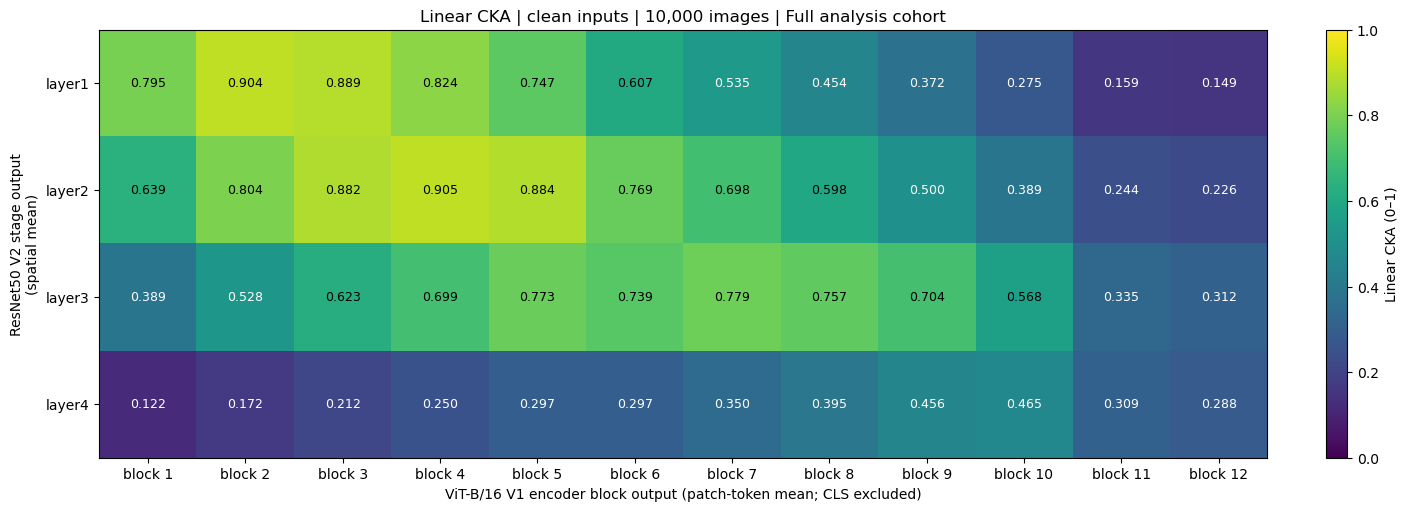

Saved CSV / metadata / heatmap for: full_20261105T011722Z_85319525


In [8]:
if RUN_EXPERIMENT:
    matrix = cka_matrix(features_by_model["resnet50"], features_by_model["vit_b_16"],
                        block_size=CKA_BLOCK_SIZE)
    def git_output(*args):
        return subprocess.check_output(["git", *args], cwd=ROOT, text=True).strip()
    packages = {}
    for package in ("numpy", "pandas", "matplotlib", "torch", "torchvision", "pyarrow", "pillow", "huggingface_hub"):
        try:
            packages[package] = importlib.metadata.version(package)
        except importlib.metadata.PackageNotFoundError:
            packages[package] = None
    metadata = dict(
        experiment="cka", run_id=RUN_ID, mode=MODE, condition="clean",
        status="full cohort completed" if FULL_RUN else "smoke test only; no research conclusions",
        completed_utc=datetime.now(timezone.utc).isoformat(), seed=SEED,
        num_images=len(records), manifest_path=config["manifest"], manifest_sha256=manifest_hash,
        checksum_newlines="LF", dataset_repo=config["dataset_repo"],
        dataset_revision=config["dataset_revision"], data_dir=str(DATA_DIR),
        dataset_files_sha256=config["dataset_files_sha256"], dataset_verification=verification,
        evaluated_ids=[r["image_id"] for r in records],
        cohort_sha256=cohort_hash, cohort_hash_encoding="UTF-8; sorted image_id TAB label LF",
        selection_rule="entire committed manifest" if FULL_RUN else f"first {SMOKE_N} manifest rows; debug only",
        exclusions=[], model_metadata=model_metadata, layers=LAYER_DIMS, pooling=POOLING,
        hook_location="complete stage/block output; ViT before final encoder.ln",
        methodology_approval="implementation proposal; pending leader review",
        centering="per-feature global mean over entire selected cohort",
        method="exact biased linear CKA, block-summed centered feature cross-products",
        feature_normalization="none beyond official image preprocessing",
        metric_schema="4 ResNet rows x 12 ViT columns; each value is whole-cohort linear CKA",
        batch_size=BATCH_SIZE, cka_block_size=CKA_BLOCK_SIZE,
        feature_dtype="float32", accumulation_dtype="float64", autocast=False,
        tf32=False, cudnn_benchmark=False, hook_checks_enabled=CHECK_HOOKS,
        cache_reused=cache_used, package_versions=packages, python_version=sys.version,
        device=str(device), device_name=torch.cuda.get_device_name(device) if device.type == "cuda" else "CPU",
        git_revision=git_output("rev-parse", "HEAD"),
        git_dirty=bool(git_output("status", "--porcelain")),
        code_sha256=code_hashes,
    )
    figure = save_results(matrix, metadata, ROOT, RUN_ID)
    table = pd.DataFrame(matrix, index=RESNET_LAYERS,
                         columns=[f"Block {i + 1}" for i in range(12)])
    display(table.round(4))
    plt.show()
    plt.close(figure)
    print("Saved CSV / metadata / heatmap for:", RUN_ID)
else:
    print("No CKA results generated.")

## 7. Phân tích kết quả

### 7.1. Mức tương đồng lớn nhất theo từng giai đoạn

| Giai đoạn ResNet-50 | Khối ViT-B/16 đạt CKA lớn nhất | CKA |
| --- | ---: | ---: |
| `layer1` | 2 | 0.9039 |
| `layer2` | 4 | 0.9046 |
| `layer3` | 7 | 0.7793 |
| `layer4` | 10 | 0.4653 |

Giá trị CKA trong toàn ma trận dao động từ **0.1222 đến 0.9046**. Cặp `layer2`–block 4 đạt giá trị lớn nhất (0.9046), tiếp theo là `layer1`–block 2 (0.9039). Chênh lệch khoảng 0.0007 giữa hai cặp chưa đủ cơ sở để khẳng định sự khác biệt có ý nghĩa thống kê, do thí nghiệm chưa ước lượng độ bất định.

### 7.2. Sự thay đổi theo độ sâu

Các giai đoạn đầu của ResNet-50 đạt tương đồng lớn nhất với những khối đầu của ViT: `layer1` tương ứng với block 2 và `layer2` với block 4. Ở độ sâu trung gian, `layer3` đạt cực đại tại block 7 (0.7793), đồng thời có giá trị gần tương đương tại block 5 (0.7731).

Giai đoạn cuối `layer4` đạt cực đại tại block 10 (0.4653), thấp hơn cực đại của các giai đoạn trước. Quan sát này cho thấy biểu diễn cuối của ResNet ít tương đồng hơn với các biểu diễn patch-mean của ViT được khảo sát. Tuy nhiên, mức CKA thấp hơn không đồng nghĩa với chất lượng đặc trưng hoặc khả năng phân loại thấp hơn.

Nhìn chung, vị trí cực đại dịch về các khối ViT sâu hơn khi độ sâu ResNet tăng. Các khối 11–12 không đạt cực đại ở bất kỳ hàng nào. Kết quả mô tả sự tương ứng theo độ sâu trong cấu hình đo hiện tại, nhưng không xác lập quan hệ tương đương chức năng giữa từng cặp tầng.

In [9]:
if RUN_EXPERIMENT:
    pairs = sorted(
        [(float(matrix[i, j]), RESNET_LAYERS[i], f"block {j + 1}", VIT_LAYERS[j])
         for i in range(4) for j in range(12)], reverse=True)
    print("SMOKE TEST — chỉ kiểm tra luồng chạy, không kết luận nghiên cứu."
          if not FULL_RUN else "Full cohort — mô tả dưới đây dựa trên ma trận đo được:")
    for score, resnet_layer, block, module in pairs[:5]:
        print(f"{resnet_layer} ↔ {block} ({module}): CKA={score:.6f}")
    for i, layer in enumerate(RESNET_LAYERS):
        j = int(matrix[i].argmax())
        print(f"Stage maximum: {layer} ↔ block {j + 1}: {matrix[i, j]:.6f}")
    print(f"Range: {matrix.min():.6f}–{matrix.max():.6f}")
else:
    print("Results pending: chưa có dữ liệu để xác định cặp tầng tương đồng nhất.")


Full cohort — mô tả dưới đây dựa trên ma trận đo được:
layer2 ↔ block 4 (encoder.layers.encoder_layer_3): CKA=0.904623
layer1 ↔ block 2 (encoder.layers.encoder_layer_1): CKA=0.903906
layer1 ↔ block 3 (encoder.layers.encoder_layer_2): CKA=0.888823
layer2 ↔ block 5 (encoder.layers.encoder_layer_4): CKA=0.883965
layer2 ↔ block 3 (encoder.layers.encoder_layer_2): CKA=0.882359
Stage maximum: layer1 ↔ block 2: 0.903906
Stage maximum: layer2 ↔ block 4: 0.904623
Stage maximum: layer3 ↔ block 7: 0.779259
Stage maximum: layer4 ↔ block 10: 0.465303
Range: 0.122231–0.904623


## 8. Thảo luận và giới hạn

Kết quả cho thấy mức tương đồng biểu diễn giữa ResNet-50 và ViT-B/16 không đồng đều theo độ sâu. Một số cặp tầng đầu và trung gian đạt CKA cao hơn rõ rệt so với cực đại của giai đoạn cuối ResNet. Điều này gợi ý hai mô hình chia sẻ một phần cấu trúc biểu diễn, đồng thời duy trì những khác biệt ở các mức xử lý sâu hơn.

Các kết luận cần được xem xét trong phạm vi thiết kế thực nghiệm:

- **Lựa chọn biểu diễn:** phép lấy trung bình loại bỏ cấu trúc không gian và vị trí token. Thí nghiệm chưa đánh giá CLS token hoặc các cách tổng hợp khác.
- **Điều kiện so sánh:** bộ trọng số, lịch sử huấn luyện và quy trình tiền xử lý đều có thể ảnh hưởng đến CKA. Resize 232/256 tạo khác biệt về vùng ảnh quan sát, nên chưa thể tách riêng tác động của kiến trúc.
- **Phạm vi đánh giá:** kết quả dựa trên một cặp mô hình và một tập ảnh; chưa có khoảng tin cậy hoặc kiểm chứng trên nhiều checkpoint và bộ dữ liệu.
- **Ý nghĩa phép đo:** CKA phản ánh sự tương đồng biểu diễn, không trực tiếp đo độ chính xác, độ bền vững hoặc quan hệ nhân quả trong dự đoán.

Do đó, kết quả CKA cần được đối chiếu với các thí nghiệm Grad-CAM, ERF và robustness của dự án để hình thành nhận định tổng thể về cách hai kiến trúc xử lý thông tin thị giác.

### Tài liệu tham khảo

1. Kornblith, S., Norouzi, M., Lee, H., & Hinton, G. (2019). [Similarity of Neural Network Representations Revisited](https://proceedings.mlr.press/v97/kornblith19a.html). *ICML*, PMLR 97, 3519–3529.
2. [ImageNet-1K validation — nguồn dữ liệu](https://huggingface.co/datasets/ILSVRC/imagenet-1k).
3. Quy ước thực nghiệm của dự án: [experiment_protocol.md](../docs/experiment_protocol.md) và [analysis_set.md](../docs/analysis_set.md).